# Lab 05: The Dark Companion, Two Years Later

**ASTR 457, Fall 2026, posted Sat Oct 3, due Fri Oct 9 by Noon (extended) (fork → PR, as always)**

*Why this lab: every orbit in the literature, from Gaia's black-hole binaries to the planets David Charbonneau talked about on Tuesday, is a posterior distribution over six or seven parameters that nobody can write down in closed form. Sampling it, knowing when the sampler has actually converged, and turning the samples into a number with an honest error bar is the core professional skill of modern astrophysics, and the place where confident, fluent, wrong analyses are most common.*

On Day 1 you watched a star's radial velocity drift over ten nights and inferred an unseen companion from
the slope alone. This is that programme, two and a half years on. Every one of you has your own star:
`data/<your netid>.csv`, with columns `t_days` (time of each spectrum, from the first epoch), `rv_kms`
(the measured radial velocity) and `sigma_rv_kms` (the pipeline's per-epoch uncertainty). The star was
observed in three observing seasons over about 900 days, 28 to 44 epochs in all. It is a **single-lined
spectroscopic binary**: you see one star's lines, the companion contributes no light, and the visible star
follows a Keplerian orbit,

$$v_r(t) = \gamma + K\left[\cos\big(\nu(t) + \omega\big) + e\cos\omega\right],$$

with period $P$, semi-amplitude $K$, eccentricity $e$, argument of periastron $\omega$, a time of periastron
$T_p$, systemic velocity $\gamma$, and $\nu(t)$ the true anomaly (the angle around the orbit, which you get
from Kepler's equation; a function is provided). What you are really after is the **mass function**

$$f(M) = \frac{P K^3 (1 - e^2)^{3/2}}{2\pi G} = \frac{M_2^3 \sin^3 i}{(M_1 + M_2)^2},$$

a lower limit on the companion's mass, in solar masses. If it comes out above about $3\,M_\odot$ for a
Sun-like primary, you have a black hole candidate, the way Gaia BH1 was found (El-Badry et al. 2023, the Sep 8
colloquium). In the units of your file, $f(M) = 1.0361\times10^{-7}\,(1-e^2)^{3/2} K^3 P$ with $K$ in km/s
and $P$ in days.

I know your true $P$, $K$, $e$ and $f(M)$. You don't, your classmates' stars are different, and so is the
sampling. **One more thing I know and you don't: the quoted `sigma_rv_kms` is not the whole error.** Real
radial velocities carry an extra scatter, called jitter, from the star's own surface and from template
mismatch, and it is not in the pipeline number.

**How this is graded.** As always, on whether your answers are *right* and your uncertainties are *honest*:
your reported $P$, $K$, $e$ and $f(M)$ are compared to your truth in units of your own reported uncertainty.
Anti-sandbagging cap: your $\sigma_K$ may not exceed $3\times$ a reference posterior width I compute for your
dataset. Padded error bars lose points like overconfident ones.

**AI policy reminder.** Use whatever tools you like, including AI assistants, and document it in Part 4. You
may be selected to defend this lab orally; the defense is easy if you did the work.

Weights: Part 1 15%, Part 2 40%, Part 3 35%, Part 4 10%.


In [28]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
from scipy.optimize import minimize
from astropy.timeseries import LombScargle
from scipy.signal import find_peaks

NETID = 'gracelh4'   # <-- set this
d = np.genfromtxt(f'data/{NETID}.csv', delimiter=',', names=True)
t, rv, sig = d['t_days'], d['rv_kms'], d['sigma_rv_kms']
print(f"{t.size} epochs over {t.max() - t.min():.0f} days; median quoted error {np.median(sig):.2f} km/s")

def kepler_rv(t, P, K, e, omega, Tp, gamma):
    """Radial velocity of the visible star in a Keplerian orbit.
    P period [d], K semi-amplitude [km/s], e eccentricity, omega argument of periastron [rad],
    Tp a time of periastron [d], gamma systemic velocity [km/s]. Solves Kepler's equation by Newton iteration."""
    M = 2. * np.pi * ((t - Tp) / P % 1.0)            # mean anomaly
    E = M.copy()                                     # eccentric anomaly
    for _ in range(30):
        E = E - (E - e * np.sin(E) - M) / (1. - e * np.cos(E))
    nu = 2. * np.arctan2(np.sqrt(1. + e) * np.sin(E / 2.), np.sqrt(1. - e) * np.cos(E / 2.))   # true anomaly
    return gamma + K * (np.cos(nu + omega) + e * np.cos(omega))

def mass_function(P, K, e):
    """f(M) in solar masses, for P in days and K in km/s."""
    return 1.0361e-7 * (1. - e**2)**1.5 * K**3 * P

35 epochs over 843 days; median quoted error 1.64 km/s


## Part 1: Look first, then find the period (15%)

Plot the radial velocities against time with their error bars. Then find candidate orbital periods with a
Lomb-Scargle periodogram of the velocities (`astropy.timeseries.LombScargle`, Day 7's periodogram, formally
taught on Oct 20/22; for now it is a tool that ranks periods). Plot the periodogram. Then, for the best two or
three candidate periods, phase-fold the data and look.

Answer, in a few sentences: how many candidate periods are plausible from the periodogram alone, and why does
a Lomb-Scargle periodogram (which fits a *sinusoid*) not settle the question for an eccentric orbit? What
feature of the sampling (look at the gaps) produces the other peaks?


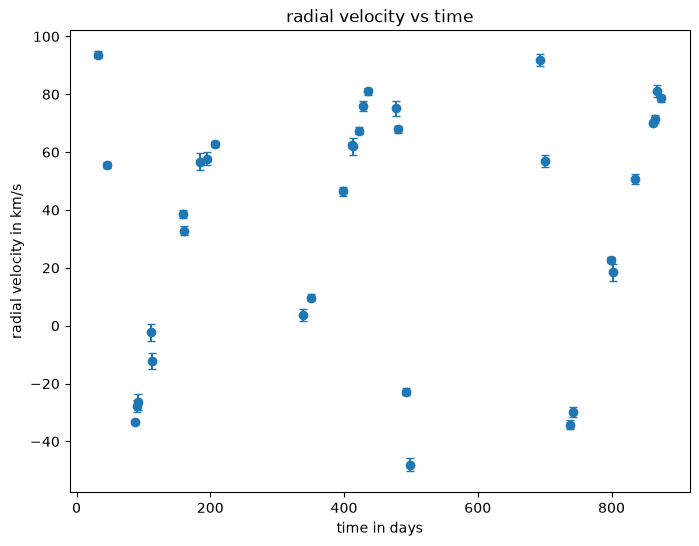

In [29]:
# Part 1: your work here

plt.figure(figsize = (8,6))
plt.errorbar(t, rv, yerr=sig, fmt = 'o', capsize = 3)
plt.xlabel('time in days')
plt.ylabel('radial velocity in km/s')
plt.title('radial velocity vs time')
plt.show()

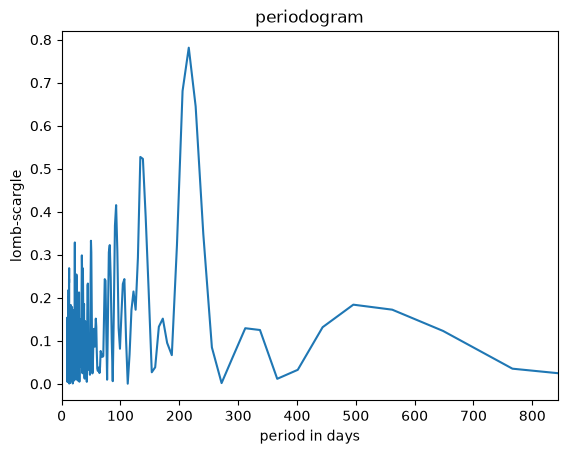

In [30]:
ls = LombScargle(t, rv, sig)
frequency, power = ls.autopower()
period = 1/frequency
plt.plot(period, power)
plt.xlabel('period in days')
plt.xlim(0, 843)
plt.ylabel('lomb-scargle')
plt.title('periodogram')
plt.show()

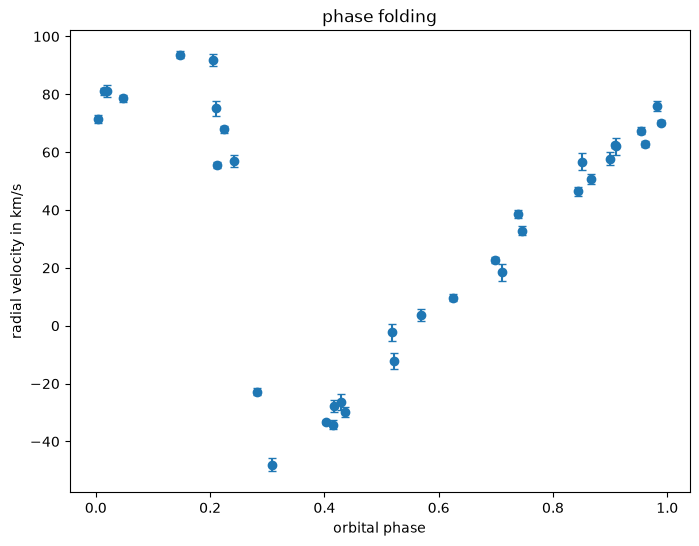

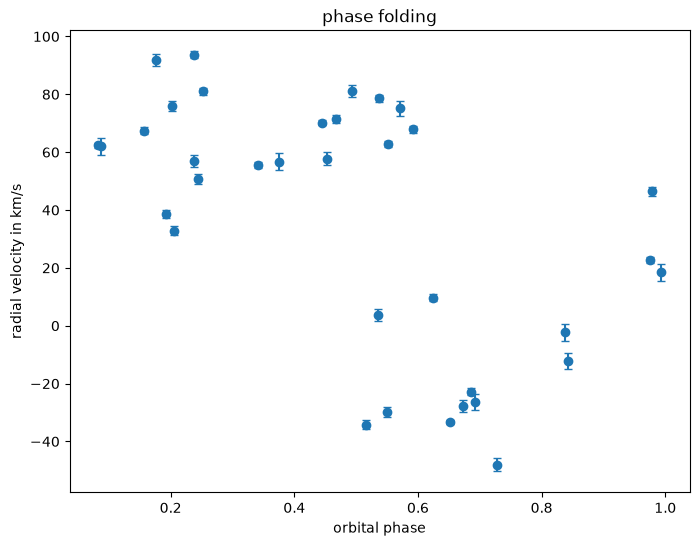

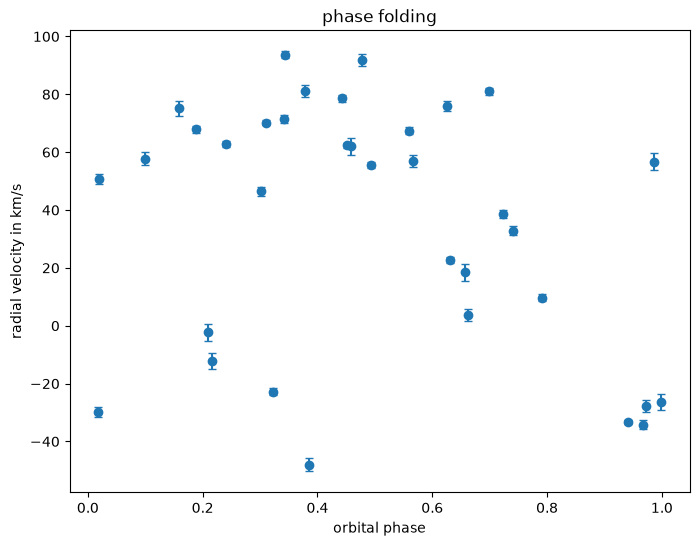

In [31]:
peaks, properties = find_peaks(power)
power[peaks]

sorted_peaks = np.argsort(power[peaks])[::-1][:3]
candidate_periods = period[peaks[sorted_peaks]]
for p in candidate_periods:
    phase = (t / p) % 1
    plt.figure(figsize = (8,6))
    plt.errorbar(phase, rv, yerr=sig, fmt='o', capsize = 3)
    plt.xlabel('orbital phase')
    plt.ylabel('radial velocity in km/s')
    plt.title('phase folding')
    plt.show()

**ANSWER (a few sentences):**

how many candidate periods are plausible from the periodogram alone?

i estimated that there were three candidates from the periodogram. there are three clear peaks shown in the graph. 

why does a Lomb-Scargle periodogram (which fits a sinusoid) not settle the question for an eccentric orbit? 

lomb-scargle is built to fit sinusodial variations, so an eccentric orbit's radial velocity would not fit that sinusodial movement. 

What feature of the sampling (look at the gaps) produces the other peaks?

there are several substainial gaps in the observing sessions over the course of 843 days. those gaps create unvertainty surrounding the number of orbital cycles occured over 843 days.

## Part 2: Sample the posterior (40%)

Fit the six orbital parameters **plus a jitter term** $s$ with `emcee`. The likelihood for epoch $i$ is
Gaussian with variance $\sigma_i^2 + s^2$; write it out (including the $\log$ of the variance, which is not a
constant once $s$ is a parameter). You will need to:

1. **Write the log-likelihood, log-prior and log-posterior.** State every prior and justify it in one line
   each. Two traps: $\omega$ and $T_p$ are periodic ($T_p$ is only defined modulo $P$), and `emcee` does not
   wrap angles, so a hard prior wall at $0$ or $2\pi$ can cut a posterior mode in half. Either bound each of
   them within half a period of your starting value, or reparameterize with $\sqrt{e}\cos\omega$ and
   $\sqrt{e}\sin\omega$ (which also gives a uniform prior on $e$ without a wall at zero). Jitter is
   positive: sample $\ln s$.
2. **Start the walkers sensibly.** A maximum-likelihood fit from each plausible Part 1 period, with several
   starting $\omega$ and $T_p$ each, then compare the log-likelihoods; start the walkers in a small ball
   around the best one. That comparison is the check: report the log-likelihood of the runner-up.
3. **Run, then decide when it is done.** Compute the integrated autocorrelation time $\tau$ for every
   parameter (`sampler.get_autocorr_time`). Here $\tau$ is about 50 to 100 steps, so 64 walkers for
   10,000 steps is plenty (a few minutes) and `emcee`'s own rule is a chain longer than $50\tau$. A
   common choice is to discard a few $\tau$ as burn-in and thin by about $\tau/2$; say what you chose
   and why. Plot the chains. If $\tau$ cannot be estimated, your chain is too short; say so and fix it.
4. **Corner plot.** Which parameters are correlated, and why physically?
5. **Report** $P$, $K$, $e$, $\gamma$, the jitter $s$, and $f(M)$, each as a median and 68% interval.
   **$f(M)$ is computed for every posterior sample**, not from the medians of $P$, $K$ and $e$; explain in
   one sentence why that matters.
6. **Posterior predictive check.** Draw a few hundred orbits from the posterior and plot them over the data,
   phase-folded at the median period. Plot the normalized residuals with the *total* error bar
   $\sqrt{\sigma_i^2 + s^2}$. Is what is left noise?

**FINAL ANSWER:** $P = $ ___ $\pm$ ___ d, $K = $ ___ $\pm$ ___ km/s, $e = $ ___ $\pm$ ___, $\gamma = $ ___ $\pm$ ___ km/s, jitter $s = $ ___ $\pm$ ___ km/s, $f(M) = $ ___ $\pm$ ___ $M_\odot$. Is your companion a black-hole candidate? One sentence.


In [32]:
#1
def log_likelihood(theta):
    P, K, e, omega, Tp, gamma, log_s = theta
    if P <= 0 or K <= 0 or not (0 <= e < 1):
        return -np.inf
    s = np.exp(log_s)
    model = kepler_rv(t, P, K, e, omega, Tp, gamma)
    variance = sig**2 + s**2
    residuals = rv - model
    log_like = -0.5 * np.sum(residuals**2 / variance + np.log(2*np.pi*variance))
    return log_like
                             
def log_prior(theta):
    P, K, e, omega, Tp, gamma, log_s = theta
    if not (50 < P < 400):
        return -np.inf
    if not (0 < K < 200):
        return -np.inf
    if not (0 <= e < 1):
        return -np.inf
    if not (omega_center - np.pi < omega < omega_center + np.pi):
        return -np.inf
    if not (Tp_center - P_center/2 < Tp < Tp_center + P_center/2):
        return -np.inf
    if not (-200 < gamma < 200):
        return -np.inf
    if not (np.log(0.01) < log_s < np.log(100)):
        return -np.inf
    return 0.0

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta)


# P: 50-400 days -->covers the three peaks found in part 1
# K: 0-200km/3 --> positive amplitude, broad range relative to observed velocities
# e: 0-1 -->orbits have eccentricities between 0 and 1
# w: -pi-pi -->one full angular cycle
#Tp: -centered on best fit
#gamma: -200 - 200 -->range for systemic velocity
#ln(s): ln(0.01)-ln(100)-->allows positive jitter over several orders of magnitude

P: 50-400, covers the three candidate periods from part 1.

K: 0-200km/s. has to be positive, and this allows amplitudes to be larger than the observed ones.

e: 0-1, elliptical orbits are bound to 0-1

omega: -pi to pi, periodic, centering it on best fit avoids a boundary passing through the best-fitting solution

Tp: centered on the best-fitting time (point closest to the star), and a half orbital period and each direction. 

gamma:  -200 to 200km/s, covers the observed systemic velocity.

ln(s), ln(0.01)-ln(100), guarantees positive jitter and allows several orders of magnitude in additional uncertainty. 

In [33]:
#2
results = []
for P0 in candidate_periods:
    best = None
    for omega0 in [0, np.pi/2, np.pi, 3*np.pi/2]:
        for Tp0 in [-P0/2, 0, P0/2]:
            for e0 in [0.2, 0.6]:
                theta0 = [P0, (rv.max() - rv.min()) / 2,e0,omega0, Tp0, np.mean(rv), np.log(np.median(sig))]
                bounds = [(0.7*P0, 1.3*P0), (0.01, 200), (0, 0.95), (-2*np.pi, 2*np.pi), (-P0, P0), (-200, 200), (np.log(0.01), np.log(100))]
                fit = minimize(lambda theta: -log_likelihood(theta),theta0, method='L-BFGS-B', bounds=bounds)
                if fit.success:
                    if best is None or fit.fun < best.fun:
                        best = fit
    if best is not None:
        results.append(best)
        print(f"Starting P = {P0:.2f} days")
        print(f"Best P = {best.x[0]:.3f} days")
        print(f"Log-likelihood = {-best.fun:.3f}")
        print()

Starting P = 216.11 days
Best P = 218.356 days
Log-likelihood = -89.399

Starting P = 133.78 days
Best P = 135.205 days
Log-likelihood = -164.819

Starting P = 92.62 days
Best P = 80.443 days
Log-likelihood = -172.994



In [34]:
results = sorted(results, key=lambda fit: fit.fun)

best_fit = results[0]
runner_up = results[1]

best_fit.x[3] = (best_fit.x[3] + np.pi) % (2*np.pi) - np.pi

print("Best log-likelihood:", -best_fit.fun)
print("Runner-up log-likelihood:", -runner_up.fun)

print("Best-fit parameters:", best_fit.x)

Best log-likelihood: -89.39858455462975
Runner-up log-likelihood: -164.81871826993267
Best-fit parameters: [218.35599185  73.57220248   0.53361915   1.72662551  51.4037957
  29.44010596   0.91459072]


In [35]:
#3
P_center = best_fit.x[0]
Tp_center = best_fit.x[4]
omega_center = best_fit.x[3]

ndim = 7
nwalkers = 64
nsteps = 10000
np.random.seed(42)
scales = np.array([0.1, 0.1, 0.005, 0.01, 0.1, 0.1, 0.01])
pos = best_fit.x + scales * np.random.randn(nwalkers, ndim)
print("Walker positions:", pos.shape)
print("All walkers valid:",
      np.all(np.isfinite([log_posterior(p) for p in pos])))

sampler = emcee.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior
)

sampler.run_mcmc(pos, nsteps, progress=True)

print("Mean acceptance fraction:",
      np.mean(sampler.acceptance_fraction))

labels = ["P", "K", "e", "omega", "Tp", "gamma", "log_s"]

tau = sampler.get_autocorr_time()

for name, value in zip(labels, tau):
    print(f"{name}: tau = {value:.2f}")

print("Minimum chain length / tau:", nsteps / np.max(tau))

Walker positions: (64, 7)
All walkers valid: True


100%|███████████████████████████████████| 10000/10000 [01:10<00:00, 142.18it/s]


Mean acceptance fraction: 0.4867921875
P: tau = 69.85
K: tau = 77.23
e: tau = 75.30
omega: tau = 73.03
Tp: tau = 74.00
gamma: tau = 73.42
log_s: tau = 74.39
Minimum chain length / tau: 129.48674026149766


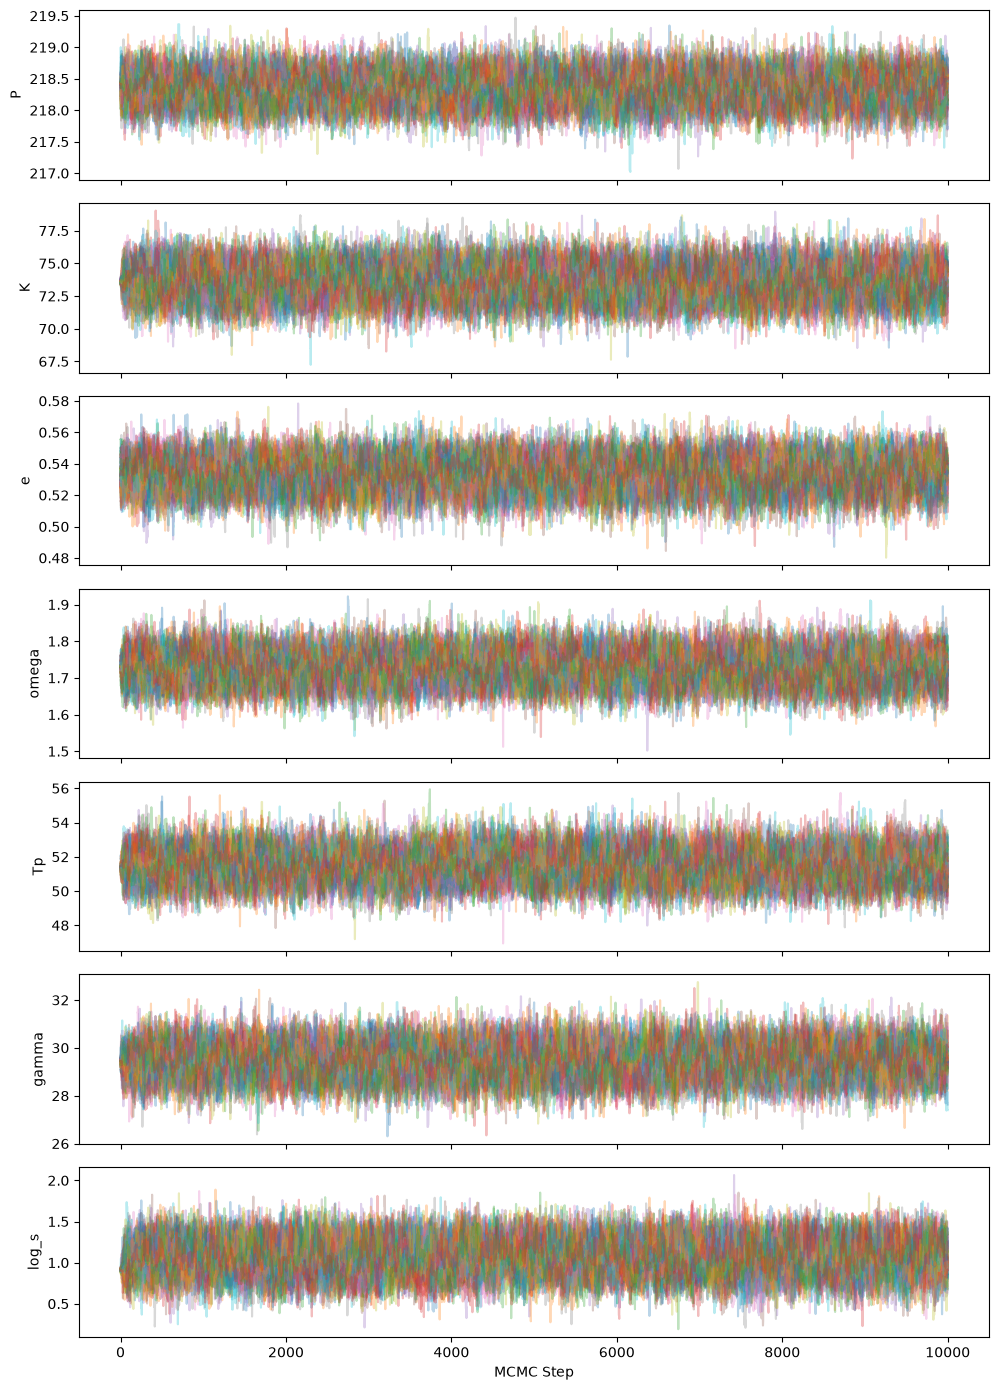

In [42]:
samples = sampler.get_chain()
fig, axes = plt.subplots(7, figsize=(10, 14), sharex=True)

for i in range(ndim):
    axes[i].plot(samples[:, :, i], alpha=0.3)
    axes[i].set_ylabel(labels[i])

axes[-1].set_xlabel("MCMC Step")
plt.tight_layout()
plt.show()

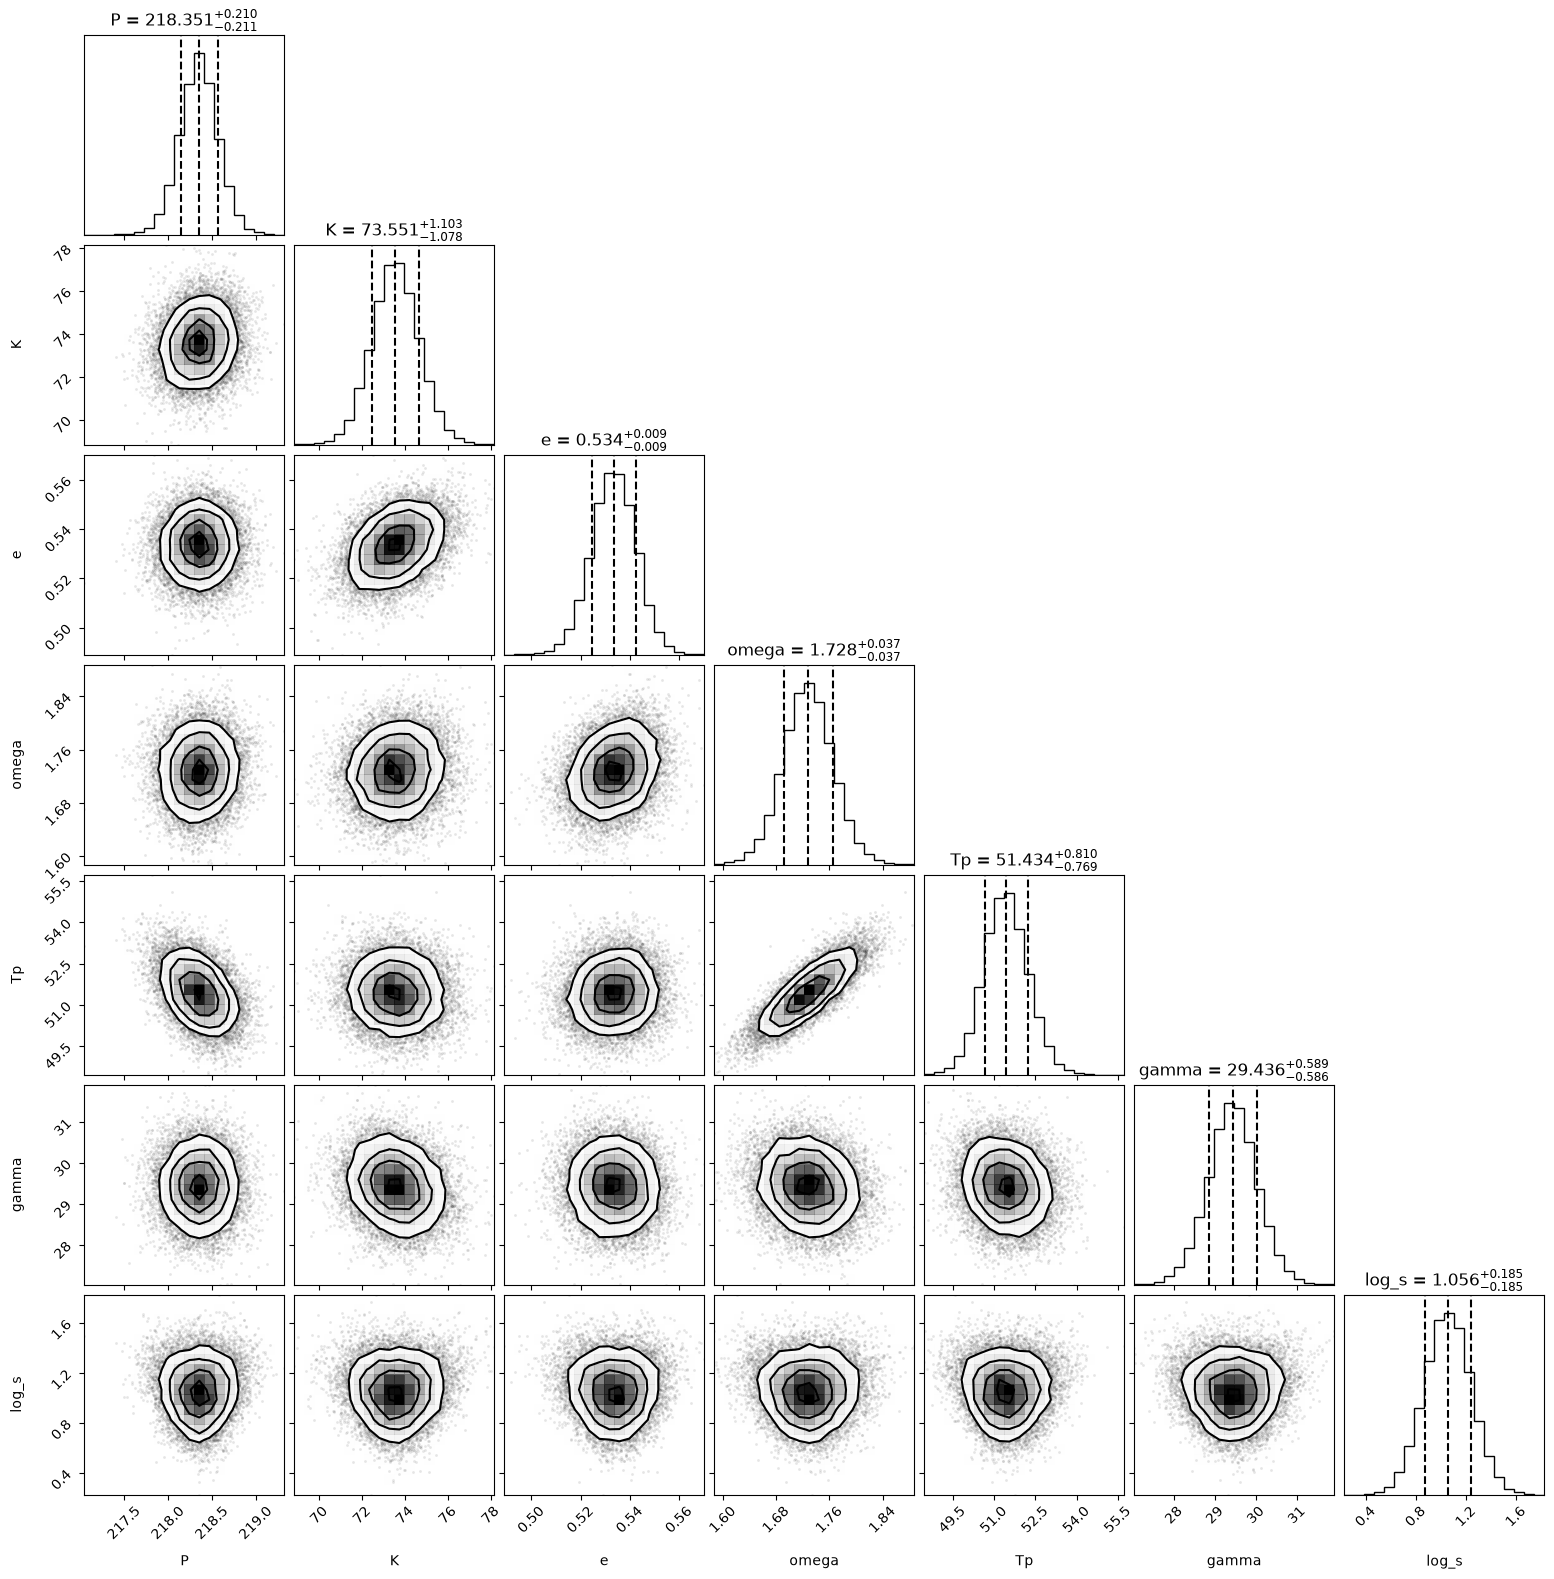

Burn-in: 231
Thinning: 38
Number of posterior samples: 16448


In [43]:
#4

burnin = int(3 * np.max(tau))
thin = max(1, int(np.max(tau) / 2))

flat_samples = sampler.get_chain(
    discard=burnin,
    thin=thin,
    flat=True)

labels = ["P", "K", "e", "omega", "Tp", "gamma", "log_s"]

fig = corner.corner(
    flat_samples,
    labels=labels,
    show_titles=True,
    title_fmt=".3f",
    quantiles=[0.16, 0.5, 0.84])

plt.show()

print("Burn-in:", burnin)
print("Thinning:", thin)
print("Number of posterior samples:", len(flat_samples))

In [44]:
corr = np.corrcoef(flat_samples, rowvar=False)

labels = ["P", "K", "e", "omega", "Tp", "gamma", "log_s"]

for i in range(len(labels)):
    for j in range(i):
        if abs(corr[i, j]) > 0.3:
            print(f"{labels[i]} and {labels[j]}: {corr[i, j]:.3f}")

e and K: 0.378
Tp and P: -0.414
Tp and omega: 0.822


e & K are positively correlated
both affect shape and amplitude of radial velocity curve, so they are correlated.

time of periastron and orbital period are negatively correlated
changes in orbital period shift the predicted orbital phases, which can be compensated by changes in periastron timing, so negatively correlated


time of periastron and argument of periastron are positively correlated
time and argument both influence the timing of features in the radial velocity curve, so they are correlated.

In [45]:
#5
P_samples = flat_samples[:, 0]
K_samples = flat_samples[:, 1]
e_samples = flat_samples[:, 2]
gamma_samples = flat_samples[:, 5]
s_samples = np.exp(flat_samples[:, 6])
fM_samples = mass_function(P_samples, K_samples, e_samples)

def summarize(samples):
    q16, q50, q84 = np.percentile(samples, [16, 50, 84])
    lower = q50 - q16
    upper = q84 - q50
    avg_uncertainty = (lower + upper) / 2
    return q50, lower, upper, avg_uncertainty

parameters = {
    "P (days)": P_samples,
    "K (km/s)": K_samples,
    "e": e_samples,
    "gamma (km/s)": gamma_samples,
    "s (km/s)": s_samples,
    "f(M) (solar masses)": fM_samples}

for name, samples in parameters.items():
    median, lower, upper, avg = summarize(samples)
    print(f"{name} = {median:.3f} ± {avg:.3f}")
    print(f"  68% interval: +{upper:.3f}, -{lower:.3f}")

P (days) = 218.351 ± 0.211
  68% interval: +0.210, -0.211
K (km/s) = 73.551 ± 1.091
  68% interval: +1.103, -1.078
e = 0.534 ± 0.009
  68% interval: +0.009, -0.009
gamma (km/s) = 29.436 ± 0.588
  68% interval: +0.589, -0.586
s (km/s) = 2.874 ± 0.535
  68% interval: +0.585, -0.485
f(M) (solar masses) = 5.445 ± 0.225
  68% interval: +0.232, -0.219


since the mass function depends nonlinearly on P, K and e, these parameters can be correlated, so calculating it for each posterior preserves their uncertainies, so creates a more accurate interval.

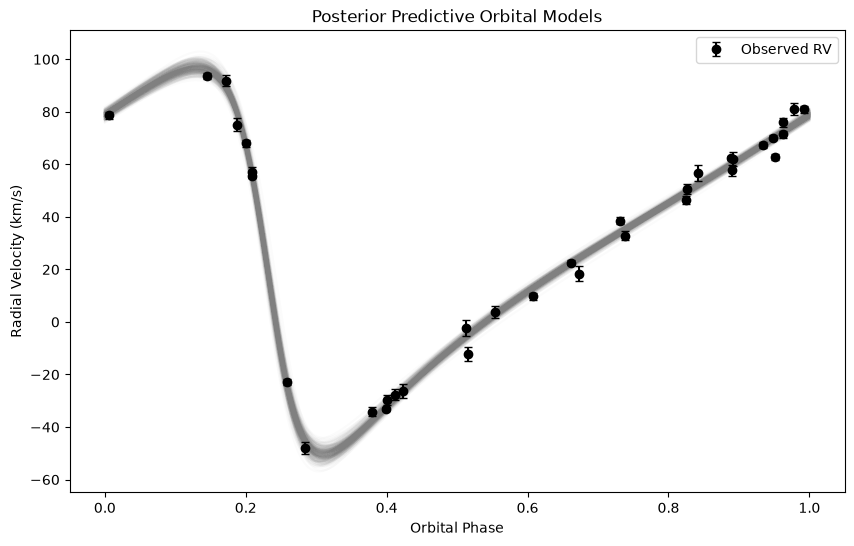

In [40]:
#6

np.random.seed(42)

indices = np.random.choice(len(flat_samples), 300, replace=True)
draws = flat_samples[indices]
P_median = np.median(flat_samples[:, 0])
t_grid = np.linspace(0, P_median, 500)
phase_grid = t_grid / P_median
plt.figure(figsize=(10, 6))
for theta in draws:
    P, K, e, omega, Tp, gamma, log_s = theta
    model = kepler_rv(t_grid, P, K, e, omega, Tp, gamma)
    plt.plot(phase_grid, model, color='gray', alpha=0.03)
phase_data = (t / P_median) % 1

plt.errorbar(
    phase_data,
    rv,
    yerr=sig,
    fmt='o',
    color='black',
    capsize=3,
    label='Observed RV')

plt.xlabel('Orbital Phase')
plt.ylabel('Radial Velocity (km/s)')
plt.title('Posterior Predictive Orbital Models')
plt.legend()
plt.show()

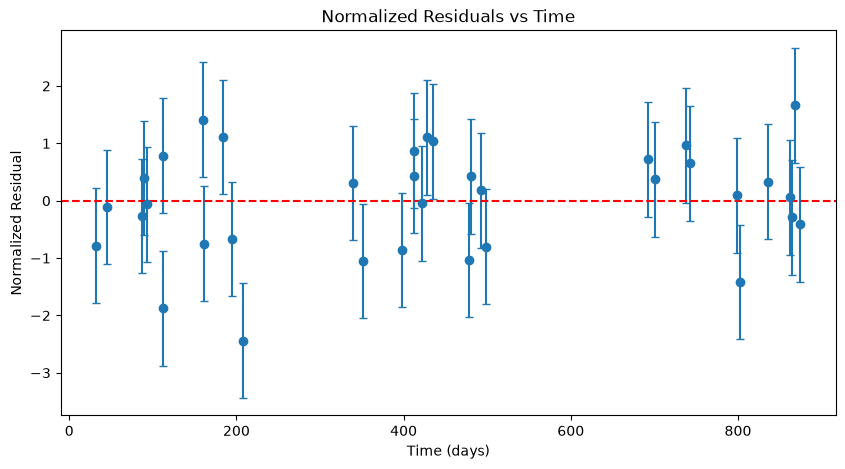

In [41]:
theta_med = np.median(flat_samples, axis=0)
P, K, e, omega, Tp, gamma, log_s = theta_med
s = np.exp(log_s)
rv_model = kepler_rv(t, P, K, e, omega, Tp, gamma)
sigma_total = np.sqrt(sig**2 + s**2)
normalized_residuals = (rv - rv_model) / sigma_total
plt.figure(figsize=(10, 5))
plt.errorbar(
    t,
    normalized_residuals,
    yerr=np.ones_like(sig),
    fmt='o',
    capsize=3)

plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Time (days)')
plt.ylabel('Normalized Residual')
plt.title('Normalized Residuals vs Time')
plt.show()

yes, consistent with random noise

In [20]:
print("Mean normalized residual:",
      np.mean(normalized_residuals))
print("Standard deviation of normalized residuals:",
      np.std(normalized_residuals, ddof=1))
print("Number of residuals beyond 3 sigma:",
      np.sum(np.abs(normalized_residuals) > 3))
print("Reduced chi-square:",
      np.sum(normalized_residuals**2) / (len(rv) - 7))

Mean normalized residual: -0.001706114885665728
Standard deviation of normalized residuals: 0.9295508144105472
Number of residuals beyond 3 sigma: 0
Reduced chi-square: 1.0492250800858822


**FINAL ANSWER:** $P = $ 218.351 $\pm$ 0.211 d, $K = $ 73.551 $\pm$ 1.091 km/s, $e = $ 0.53 $\pm$ 0.009 , $\gamma = $ 29.436 $\pm$ 0.588 km/s, $s = $ 2.874 $\pm$ 0.535 km/s, $f(M) = $ 5.445 $\pm$ 0.225 $M_\odot$

**Black-hole candidate?** *Since the mass exceeds 3 M star, the companion is a black hole.*

## Part 3: The referee report (35%)

The file `ai_solution.ipynb` in this directory is a complete, tidy, confident MCMC analysis of this exact
problem, produced by an AI assistant. It runs top to bottom without errors, the corner plot is handsome, and
the prose is fluent. It is also wrong, in at least **three** distinct, substantive ways (cosmetic nitpicks and
style don't count; "it used 24 walkers and I used 32" is not a finding).

Write a referee report:

1. **Identify** at least three substantive statistical errors.
2. **Demonstrate** each one quantitatively on *your* dataset: show, with a number or a plot, what the error
   does to the inference. For a sampler, "demonstrate" usually means running it the wrong way and the right
   way and comparing. A demonstration can come out negative: if an error turns out not to move *your*
   numbers, showing that, and saying what it would take for it to bite, is a valid finding.
3. **State** the correct treatment (you built it in Part 2).

Third time you have done this. You should be finding these in minutes now.


In [ ]:
# Part 3: your work here

# 1


In [46]:
#Mistake 1:

# My code:
def log_likelihood(theta):
    P, K, e, omega, Tp, gamma, log_s = theta
    if P <= 0 or K <= 0 or not (0 <= e < 1):
        return -np.inf
    s = np.exp(log_s)
    model = kepler_rv(t, P, K, e, omega, Tp, gamma)
    variance = sig**2 + s**2
    residuals = rv - model
    log_like = -0.5 * np.sum(residuals**2 / variance + np.log(2*np.pi*variance))
    return log_like

#AI Code
def log_likelihood(theta):
    model = kepler_rv(t, *theta)
    return -0.5 * np.sum(((rv - model) / sig)**2)

# This code does not take into account the jitter, which influences the uncertainties
# in the results. That means it is underestimating the uncertainies, so the true value
# could lie outside. 

ai_errors = {
    "P": 0.0910,
    "K": 0.5063,
    "e": 0.0040,
    "gamma": 0.2577,
    "f(M)": 0.121}

my_samples = {
    "P": P_samples,
    "K": K_samples,
    "e": e_samples,
    "gamma": gamma_samples,
    "f(M)": fM_samples}

print(f"{'Parameter':<12} {'AI error':<12} {'My error':<12} {'Ratio':<10}")
for name, samples in my_samples.items():
    q16, q50, q84 = np.percentile(samples, [16, 50, 84])

    my_error = ((q50 - q16) + (q84 - q50)) / 2
    ai_error = ai_errors[name]

    ratio = my_error / ai_error

    print(f"{name:<12} {ai_error:<12.4f} {my_error:<12.4f} {ratio:<10.2f}")

# each error in the AI solution is much smaller than mine. 
# The correct treatment is to take into account the jitter when calculating the uncertainty

Parameter    AI error     My error     Ratio     
P            0.0910       0.2107       2.32      
K            0.5063       1.0906       2.15      
e            0.0040       0.0089       2.23      
gamma        0.2577       0.5878       2.28      
f(M)         0.1210       0.2254       1.86      


In [53]:
#Mistake 2

# "emcee's own rule is a chain longer than 50T"

#AI Code:
# ndim, nwalkers, nsteps, nburn = 6, 24, 1500, 100
# rng = np.random.default_rng(42)
# p0 = theta_map + 1e-3 * rng.normal(size=(nwalkers, ndim))
# p0[:, 4] = np.abs(p0[:, 4])   # keep the periastron time inside its prior range
# sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)
# sampler.run_mcmc(p0, nsteps, progress=False)
# chain = sampler.get_chain()

# My code:
ndim = 7
nwalkers = 64
nsteps = 10000
np.random.seed(42)
scales = np.array([0.1, 0.1, 0.005, 0.01, 0.1, 0.1, 0.01])
pos = best_fit.x + scales * np.random.randn(nwalkers, ndim)
print("Walker positions:", pos.shape)
print("All walkers valid:",
      np.all(np.isfinite([log_posterior(p) for p in pos])))

sampler = emcee.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior)

sampler.run_mcmc(pos, nsteps, progress=True)
chain = sampler.get_chain()
short_chain = chain[:1500]
full_chain = chain
tau_short = emcee.autocorr.integrated_time(
    short_chain, tol=0)
tau_full = sampler.get_autocorr_time()
print("SHORT CHAIN (1500 steps)")
print("Maximum tau:", np.max(tau_short))
print("N/tau:", 1500 / np.max(tau_short))

print("\nFULL CHAIN (10000 steps)")
print("Maximum tau:", np.max(tau_full))
print("N/tau:", 10000 / np.max(tau_full))
short_samples = short_chain[100:].reshape(-1, ndim)

full_burnin = int(3 * np.max(tau_full))
full_samples = sampler.get_chain(
    discard=full_burnin,
    flat=True)
labels = ["P", "K", "e", "omega", "Tp", "gamma", "log_s"]

print("\nPARAMETER COMPARISON")
print(f"{'Parameter':<12} {'Short median':<15} {'Full median':<15} "
      f"{'Short SD':<12} {'Full SD':<12}")
for i, name in enumerate(labels):
    short_med = np.median(short_samples[:, i])
    full_med = np.median(full_samples[:, i])
    short_sd = np.std(short_samples[:, i])
    full_sd = np.std(full_samples[:, i])
    print(f"{name:<12} {short_med:<15.4f} {full_med:<15.4f} "
          f"{short_sd:<12.4f} {full_sd:<12.4f}")

AI error (no covariance): 0.2721 Msun
Error including covariance: 0.2313 Msun
Posterior sample error: 0.2254 Msun
Difference due to covariance: -0.0408 Msun
Difference between AI and posterior: -0.0467 Msun
K-e correlation: 0.378


In [54]:
#Mistake 3

#AI Code:
# fM_err = np.sqrt((df_dP * sd[0])**2 + (df_dK * sd[1])**2 + (df_de * sd[2])**2)


# Here, the AI calculates the uncertainty in the mass function
# without taking into account the correlations between parameters

# I recommend taking those into account here: 
P_samples = flat_samples[:, 0]
K_samples = flat_samples[:, 1]
e_samples = flat_samples[:, 2]
gamma_samples = flat_samples[:, 5]
s_samples = np.exp(flat_samples[:, 6])
fM_samples = mass_function(P_samples, K_samples, e_samples)



# Mistake 3: Compare uncertainty propagation methods


P_samples = flat_samples[:, 0]
K_samples = flat_samples[:, 1]
e_samples = flat_samples[:, 2]

P_m = np.median(P_samples)
K_m = np.median(K_samples)
e_m = np.median(e_samples)

fM = mass_function(P_m, K_m, e_m)
df_dP = fM / P_m
df_dK = 3 * fM / K_m
df_de = -3 * e_m * fM / (1 - e_m**2)

derivatives = np.array([df_dP, df_dK, df_de])
sd = np.std(flat_samples[:, :3], axis=0)

ai_error = np.sqrt(np.sum((derivatives * sd)**2))
cov = np.cov(flat_samples[:, :3], rowvar=False)

covariance_error = np.sqrt(
    derivatives @ cov @ derivatives)
fM_samples = mass_function(P_samples, K_samples, e_samples)

q16, q50, q84 = np.percentile(fM_samples, [16, 50, 84])

posterior_error = (q84 - q16) / 2
print(f"AI error (no covariance): {ai_error:.4f} Msun")
print(f"Error including covariance: {covariance_error:.4f} Msun")
print(f"Posterior sample error: {posterior_error:.4f} Msun")

print(f"Difference due to covariance: {covariance_error - ai_error:.4f} Msun")
print(f"Difference between AI and posterior: {posterior_error - ai_error:.4f} Msun")

print(f"K-e correlation: {np.corrcoef(K_samples, e_samples)[0,1]:.3f}")

# when covariance is accounted for, the uncertainty is reduced. 
# i recommend taking the correlation into account


AI error (no covariance): 0.2721 Msun
Error including covariance: 0.2313 Msun
Posterior sample error: 0.2254 Msun
Difference due to covariance: -0.0408 Msun
Difference between AI and posterior: -0.0467 Msun
K-e correlation: 0.378


**REFEREE REPORT:**

*your report goes here*

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools did you use, for what, what did they get wrong, and how did you catch it? Honesty
   is graded; "I didn't use any" is fine if true.
2. **Reflection (new from this lab on, two or three sentences)**: what did you use AI for in this lab, and
   what would have gone wrong in your answer if you had not checked its output? Name the specific thing, not
   "it could have made a mistake".
3. **Verification plan**: the checks you ran before trusting your Part 2 numbers, and what failure would have
   looked like for each. One you should seriously consider: generate a synthetic RV curve with parameters
   you choose, at *your* epochs, run your whole Part 2 pipeline on it, and see whether the 68% intervals
   contain what you put in. With seven parameters and one realisation, expect about five of seven inside
   their 68% intervals; one pull of 2.5σ is not a failure by itself. Failure looks systematic: the same
   parameter off in the same direction every time, or an interval that never contains the truth.



**REFLECTION:**

I used AI for a lot of the coding in this lab. If I was not careful, it could have overdone uncertainty calculations--I have found that Chat often goes overboard on assuming errors, causing the uncertainty to skyrocket.

**VERIFICATION PLAN:**

I compared the maximum likelihoods of three candidate periods. If there was a failure, then there would have been a better candidate that fit the data better. 

I ensured that the N/T max was greater than 50--the requirement for the emcee library. It is was less, that would mean an immediate error. 

I plotted orbital models and calculated the normalized residuals. If there was an error, the residuals would have been large or the reduced chi^2 would be substainially different from one.

I followed the suggestion in the verification plan below. While three of the results are outside of 68%, they are just a touch above the high end boundary. 

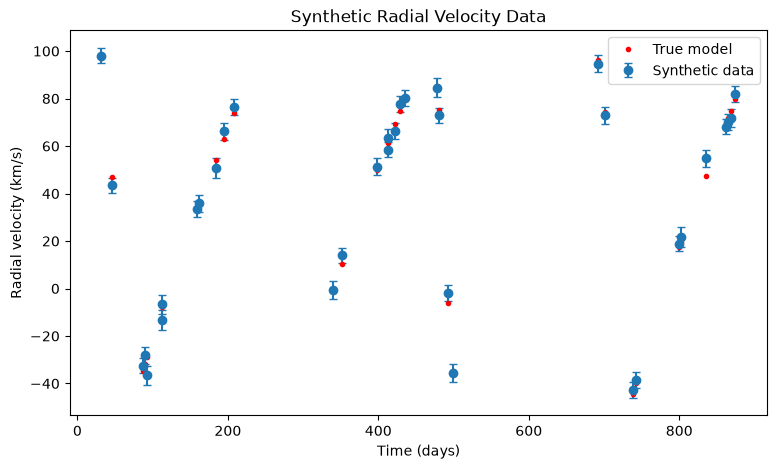

All synthetic walkers valid: True


100%|███████████████████████████████████| 10000/10000 [01:10<00:00, 142.45it/s]



Maximum autocorrelation time: 74.25097007276561
N / maximum tau: 134.67837511348398

SYNTHETIC RECOVERY RESULTS
Parameter  True         Median       68% lower    68% upper    Recovered?
P          220.0000     220.0915     219.8973     220.2862     True
K          75.0000      73.8509      72.9355      74.7876      False
e          0.5000       0.4915       0.4830       0.4999       False
omega      1.7000       1.6990       1.6660       1.7319       True
Tp         50.0000      49.7796      49.1153      50.4633      True
gamma      30.0000      30.4291      29.9023      30.9346      True
log_s      1.0986       0.8407       0.6173       1.0448       False

Parameters recovered within 68% intervals: 4/7


In [55]:
P_true = 220.0
K_true = 75.0
e_true = 0.5
omega_true = 1.7
Tp_true = 50.0
gamma_true = 30.0
s_true = 3.0

true_theta = np.array([
    P_true, K_true, e_true,
    omega_true, Tp_true, gamma_true,
    np.log(s_true)])

rng = np.random.default_rng(42)

rv_true = kepler_rv(
    t, P_true, K_true, e_true,
    omega_true, Tp_true, gamma_true)

sigma_synthetic = np.sqrt(sig**2 + s_true**2)

rv_synthetic = rv_true + rng.normal(
    0, sigma_synthetic, size=len(t))

plt.figure(figsize=(9, 5))
plt.errorbar(t, rv_synthetic, yerr=sigma_synthetic,
             fmt='o', capsize=3, label='Synthetic data')
plt.plot(t, rv_true, 'r.', label='True model')
plt.xlabel('Time (days)')
plt.ylabel('Radial velocity (km/s)')
plt.title('Synthetic Radial Velocity Data')
plt.legend()
plt.show()

def synthetic_log_likelihood(theta):
    P, K, e, omega, Tp, gamma, log_s = theta
    if P <= 0 or K <= 0 or not (0 <= e < 1):
        return -np.inf
    s = np.exp(log_s)
    model = kepler_rv(t, P, K, e, omega, Tp, gamma)
    variance = sig**2 + s**2
    return -0.5 * np.sum(
        (rv_synthetic - model)**2 / variance
        + np.log(2 * np.pi * variance))

def synthetic_log_posterior(theta):
    lp = log_prior(theta)

    if not np.isfinite(lp):
        return -np.inf

    return lp + synthetic_log_likelihood(theta)

ndim_synthetic = 7
nwalkers_synthetic = 64
nsteps_synthetic = 10000

scales = np.array([
    0.1, 0.1, 0.005, 0.01, 0.1, 0.1, 0.01])

pos_synthetic = (
    true_theta
    + scales * rng.normal(size=(nwalkers_synthetic, ndim_synthetic)))

print("All synthetic walkers valid:",
      np.all(np.isfinite([
          synthetic_log_posterior(p) for p in pos_synthetic])))

sampler_synthetic = emcee.EnsembleSampler(
    nwalkers_synthetic,
    ndim_synthetic,
    synthetic_log_posterior)

sampler_synthetic.run_mcmc(
    pos_synthetic,
    nsteps_synthetic,
    progress=True)

tau_synthetic = sampler_synthetic.get_autocorr_time()

print("\nMaximum autocorrelation time:",np.max(tau_synthetic))

print("N / maximum tau:",nsteps_synthetic / np.max(tau_synthetic))

burnin_synthetic = int(3 * np.max(tau_synthetic))
thin_synthetic = max(1, int(np.max(tau_synthetic) / 2))

synthetic_samples = sampler_synthetic.get_chain(
    discard=burnin_synthetic,
    thin=thin_synthetic,
    flat=True)
labels_synthetic = [
    "P", "K", "e", "omega", "Tp", "gamma", "log_s"]

print("\nSYNTHETIC RECOVERY RESULTS")
print(f"{'Parameter':<10} {'True':<12} {'Median':<12} "
      f"{'68% lower':<12} {'68% upper':<12} {'Recovered?'}")

n_recovered = 0

for i, label in enumerate(labels_synthetic):
    q16, q50, q84 = np.percentile(
        synthetic_samples[:, i], [16, 50, 84])
    recovered = q16 <= true_theta[i] <= q84
    if recovered:
        n_recovered += 1

    print(
        f"{label:<10} "
        f"{true_theta[i]:<12.4f} "
        f"{q50:<12.4f} "
        f"{q16:<12.4f} "
        f"{q84:<12.4f} "
        f"{str(recovered)}")

print(f"\nParameters recovered within 68% intervals: "
      f"{n_recovered}/7")

**AI-USE APPENDIX:**

I used ChatGPT as my AI of choice.

Needed help installing astropy and emcee because they were not there.

Part 1:
Requested an explaination of the variables in the given code. Without prompting Chat did provide the code for part 1.
I needed help with the Lomb-Scargle part as I have not used it before. 
I wanted to find the peaks and Chat recommended scipy.signal's find_peaks. Chat helped me with the code to find the peaks for the phase folding.


Part2:
I requested the boilerplate code for this (for each step).

I requested an explaination for several parts of the code, and why it reached that solution, to help me write the answers for the questions in step 2. 


Part 3:

I checked with Chat that the first error I caught was indeed an error. I then asked it to give me the code to demonstrate that error. 

I checked with Chat that the second error was indeed an error--I was suspicious but unsure. I requested an explaination to make sure. I requested the code to demonstrate that error as well. 

I checked other areas I thought were suspicious but not real errors, just different from mine.

I knew there was an error in step 6, but I could not find where exactly. Chat confirmed the exact location. I requested an explaination of why that was an error. Requested the code to prove it. 

Discussed an error in length that I found for Mistake 3--I 